# EDA Análisis exploratorio de comercios y transacciones

#### Objetivo general

Realizar un análisis exploratorio de la información de comercios y transacciones de los últimos seis meses disponibles, con el propósito de evaluar la estructura y calidad de los datos e identificar las variables que permitan construir posteriormente una segmentación de comercios.

#### Objetivos específicos

- Comprender la estructura y granularidad de las fuentes de información.
- Identificar la cantidad de comercios, terminales y periodos disponibles.
- Evaluar la completitud, consistencia y calidad de los datos.
- Analizar la relación entre comercios, terminales y transacciones.
- Examinar el comportamiento mensual de la actividad transaccional.
- Explorar la distribución de las ventas y las transacciones.
- Identificar valores atípicos y posibles anomalías.
- Establecer las reglas necesarias para preparar la base de segmentación.

#### Alcance

En esta etapa se realizará únicamente el análisis exploratorio de los datos. La limpieza definitiva, la construcción de variables, la segmentación y el cálculo de KPIs se desarrollarán en sus notebooks respectivos.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#config
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid", palette="muted")

### 1. Cargue de datos 

In [2]:
archivo = "../data/raw/DataTransacciones_PruebasIngreso.xlsx"

comercios = pd.read_excel(
    archivo,
    sheet_name="comercios",
    dtype={"Id_comercio": "string", "Id_terminal": "string"}
)

transacciones = pd.read_excel(
    archivo,
    sheet_name="transacciones",
    dtype={"Id_comercio": "string"}
)

In [3]:
display(comercios.head())
display(transacciones.head())

,Id_comercio,Fecha vinculación datafono,Fecha de creacion comercio,Categoria comercio,Sub Categoria comercio,Id_terminal,Ciudad,Fecha 1ra_transaccion,Monto ventas Acumulado,Monto ventas ultimo mes
0,003QDVFJCJ,"mar. 26, 2021 12:40pm","mar. 26, 2021 12:17pm",Comercio detallista,Ropa / Accesorios,01299,Bogotá D.C.,"mar. 26, 2021 12:42pm",6542000,1240000
1,008LJH6YHN,"feb. 10, 2021 3:31pm","feb. 10, 2021 3:15pm",Belleza y cuidado personal,Spa,00591,Bogotá D.C.,"feb. 10, 2021 3:34pm",4380000,1102000
2,00B3DGV62G,"mar. 3, 2021 3:26pm","mar. 3, 2021 3:09pm",Comercio detallista,Auto partes,02130,Bogotá D.C.,"mar. 3, 2021 3:30pm",11892500,1297000
3,00ILW1BB3Y,"mar. 24, 2021 12:45pm","mar. 24, 2021 12:33pm",Comercio detallista,Tienda naturista,00662,Bogotá D.C.,"mar. 24, 2021 12:51pm",372500,74500
4,01AK7UX4UU,"mar. 30, 2021 1:50pm","mar. 30, 2021 1:40pm",Comercio detallista,Tecnología,01784,Mosquera,"mar. 30, 2021 1:52pm",165500,0


,Id_comercio,mes-anio transaccion,cantidad transacciones
0,003QDVFJCJ,3-2021,5
1,003QDVFJCJ,4-2021,9
2,003QDVFJCJ,5-2021,16
3,008LJH6YHN,2-2021,2
4,008LJH6YHN,3-2021,5


### 2. Estructura y granularidad

In [4]:
print("Comercios:", comercios.shape)
print("Transacciones:", transacciones.shape)

comercios_unicos_base_comercios = comercios["Id_comercio"].nunique()
terminales_unicas = comercios["Id_terminal"].nunique()
comercios_unicos_transacciones = transacciones["Id_comercio"].nunique()

print(f"Comercios únicos en comercios: {comercios_unicos_base_comercios:,}")
print(f"Terminales únicas en comercios: {terminales_unicas:,}")
print(f"Comercios únicos en transacciones: {comercios_unicos_transacciones:,}")

Comercios: (3071, 10)
Transacciones: (8357, 3)
Comercios únicos en comercios: 3,015
Terminales únicas en comercios: 3,071
Comercios únicos en transacciones: 3,015


In [5]:
terminales_por_comercio = (
    comercios.groupby("Id_comercio")["Id_terminal"]
    .nunique())

# comercios en relación a la cantidad de terminales que tienen
comercios_multiterminal = terminales_por_comercio[
    terminales_por_comercio > 1]
comercios_uniterminal = terminales_por_comercio[
    terminales_por_comercio == 1]

print("Comercios con más de un terminal:",
      len(comercios_multiterminal))

print("Comercios con una terminal:",
      len(comercios_uniterminal))

print("Máximo de terminales por comercio:",
      terminales_por_comercio.max())

Comercios con más de un terminal: 48
Comercios con una terminal: 2967
Máximo de terminales por comercio: 5


In [6]:
print("Información de comercios:")
comercios.info()

print("\nInformación de transacciones:")
transacciones.info()

Información de comercios:
<class 'pandas.DataFrame'>
RangeIndex: 3071 entries, 0 to 3070
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Id_comercio                 3071 non-null   string
 1   Fecha vinculación datafono  3071 non-null   str   
 2   Fecha de creacion comercio  3071 non-null   str   
 3   Categoria comercio          3071 non-null   str   
 4   Sub Categoria comercio      3071 non-null   str   
 5   Id_terminal                 3071 non-null   string
 6   Ciudad                      3071 non-null   str   
 7   Fecha 1ra_transaccion       3050 non-null   str   
 8   Monto ventas Acumulado      3071 non-null   int64 
 9   Monto ventas ultimo mes     3071 non-null   int64 
dtypes: int64(2), str(6), string(2)
memory usage: 240.1 KB

Información de transacciones:
<class 'pandas.DataFrame'>
RangeIndex: 8357 entries, 0 to 8356
Data columns (total 3 columns):
 #   Column          

#### Conclusiones sobre la estructura original

- La base comercios contiene 3.071 registros y 10 variables.
- La base transacciones contiene 8.357 registros y 3 variables.
- Los identificadores Id_comercio e Id_terminal fueron cargados como texto para conservar su formato.
- Los montos de ventas y la cantidad de transacciones se encuentran en formato numérico.
- Las variables relacionadas con fechas están almacenadas como texto y deberán convertirse antes del análisis temporal.
- La variable Fecha 1ra_transaccion presenta una cantidad de valores no nulos inferior al total de registros.
- La base transacciones presenta varias observaciones para un mismo comercio, aparentemente asociadas a diferentes meses.

### 3. Calidad de los datos

##### 3.1 Nulos

In [7]:
nulos_comercios = pd.DataFrame({
    "Cantidad_nulos": comercios.isna().sum(),
    "Porcentaje_nulos": comercios.isna().mean() * 100
})

nulos_transacciones = pd.DataFrame({
    "Cantidad_nulos": transacciones.isna().sum(),
    "Porcentaje_nulos": transacciones.isna().mean() * 100
})

print("Valores faltantes en comercios:")
display(nulos_comercios)

print("Valores faltantes en transacciones:")
display(nulos_transacciones)

Valores faltantes en comercios:


,Cantidad_nulos,Porcentaje_nulos
Id_comercio,0,0.00
Fecha vinculación datafono,0,0.00
Fecha de creacion comercio,0,0.00
Categoria comercio,0,0.00
Sub Categoria comercio,0,0.00
Id_terminal,0,0.00
Ciudad,0,0.00
Fecha 1ra_transaccion,21,0.68
Monto ventas Acumulado,0,0.00
Monto ventas ultimo mes,0,0.00


Valores faltantes en transacciones:


,Cantidad_nulos,Porcentaje_nulos
Id_comercio,0,0.00
mes-anio transaccion,0,0.00
cantidad transacciones,0,0.00


##### 3.2 Duplicados 

In [8]:
duplicados_exactos_comercios = comercios.duplicated().sum()
duplicados_exactos_transacciones = transacciones.duplicated().sum()

# Combinaciones de comercio y terminal duplicadas en comercios
duplicados_comercio_terminal = comercios.duplicated(
    subset=["Id_comercio", "Id_terminal"]
).sum()

# Combinaciones de comercio y mes duplicadas en transacciones
duplicados_comercio_mes = transacciones.duplicated(
    subset=["Id_comercio", "mes-anio transaccion"]
).sum()

print(f"Filas exactas duplicadas en comercios: {duplicados_exactos_comercios}")
print(f"Filas exactas duplicadas en transacciones: {duplicados_exactos_transacciones}")
print(f"Combinaciones comercio-terminal duplicadas: {duplicados_comercio_terminal}")
print(f"Combinaciones comercio-mes duplicadas: {duplicados_comercio_mes}")

Filas exactas duplicadas en comercios: 0
Filas exactas duplicadas en transacciones: 0
Combinaciones comercio-terminal duplicadas: 0
Combinaciones comercio-mes duplicadas: 0


##### 3.3 Validaciones

In [9]:
validaciones_numericas = pd.Series({
    "Transacciones negativas":
        (transacciones["cantidad transacciones"] < 0).sum(),

    "Transacciones iguales a cero":
        (transacciones["cantidad transacciones"] == 0).sum(),

    "Ventas acumuladas negativas":
        (comercios["Monto ventas Acumulado"] < 0).sum(),

    "Ventas del último mes negativas":
        (comercios["Monto ventas ultimo mes"] < 0).sum(),

    "Ventas del último mes mayores que las acumuladas":
        (comercios["Monto ventas ultimo mes"]
         > comercios["Monto ventas Acumulado"]).sum(),

    "Registros con ventas acumuladas iguales a cero":
        (comercios["Monto ventas Acumulado"] == 0).sum(),

    "Registros con ventas del último mes iguales a cero":
        (comercios["Monto ventas ultimo mes"] == 0).sum()
})

display(validaciones_numericas.to_frame(name="Cantidad"))

,Cantidad
Transacciones negativas,0
Transacciones iguales a cero,0
Ventas acumuladas negativas,0
Ventas del último mes negativas,0
Ventas del último mes mayores que las acumuladas,0
Registros con ventas acumuladas iguales a cero,21
Registros con ventas del último mes iguales a cero,1269


In [10]:
# Verificar registros con fecha nula y ventas acumuladas en cero
registros_revision = comercios[
    comercios["Fecha 1ra_transaccion"].isna()
    & (comercios["Monto ventas Acumulado"] == 0)
]

print("Registros con fecha nula y ventas acumuladas en cero:",
      len(registros_revision))

Registros con fecha nula y ventas acumuladas en cero: 21


In [11]:
# Validar que ningún registro tenga categorias y ciudades diferentes
columnas_categoricas = [
    "Categoria comercio",
    "Sub Categoria comercio",
    "Ciudad"
]

for columna in columnas_categoricas:
    inconsistencias = (
        comercios.groupby("Id_comercio")[columna]
        .nunique(dropna=False)
        .gt(1)
        .sum()
    )

    print(
        f"Comercios con más de un valor en {columna}: "
        f"{inconsistencias}"
    )

Comercios con más de un valor en Categoria comercio: 0
Comercios con más de un valor en Sub Categoria comercio: 0
Comercios con más de un valor en Ciudad: 0


In [12]:
# Consolidar las terminales de cada comercio
ventas_por_comercio = (
    comercios.groupby("Id_comercio")
    .agg({
        "Id_terminal": "nunique",
        "Categoria comercio": "first",
        "Sub Categoria comercio": "first",
        "Ciudad": "first",
        "Monto ventas Acumulado": "sum",
        "Monto ventas ultimo mes": "sum"
    })
    .reset_index()
)

ventas_por_comercio.columns = [
    "Id_comercio",
    "Numero_terminales",
    "Categoria",
    "Subcategoria",
    "Ciudad",
    "Ventas_acumuladas",
    "Ventas_ultimo_mes"
]

print("Filas:", len(ventas_por_comercio))
print("Comercios únicos:", ventas_por_comercio["Id_comercio"].nunique())

display(ventas_por_comercio)

Filas: 3015
Comercios únicos: 3015


,Id_comercio,Numero_terminales,Categoria,Subcategoria,Ciudad,Ventas_acumuladas,Ventas_ultimo_mes
0,003QDVFJCJ,1,Comercio detallista,Ropa / Accesorios,Bogotá D.C.,6542000,1240000
1,008LJH6YHN,1,Belleza y cuidado personal,Spa,Bogotá D.C.,4380000,1102000
2,00B3DGV62G,1,Comercio detallista,Auto partes,Bogotá D.C.,11892500,1297000
3,00ILW1BB3Y,1,Comercio detallista,Tienda naturista,Bogotá D.C.,372500,74500
4,01AK7UX4UU,1,Comercio detallista,Tecnología,Mosquera,165500,0
...,...,...,...,...,...,...,...
3010,ZYU8UUM32R,1,Comercio detallista,Tecnología,Bogotá D.C.,26110920,4912000
3011,ZYV1ZCZ7IM,1,Servicios,Tecnología y software,Bogotá D.C.,4400500,491000
3012,ZZJ3KWF9VC,1,Alimentos y bebidas,Restaurante / Café,Bogotá D.C.,65100,20000
3013,ZZMG2NE0Q6,1,Comercio detallista,Elementos de seguridad,Bogotá D.C.,300000,149000


In [13]:
print(
    "Comercios con ventas acumuladas en cero:",
    (ventas_por_comercio["Ventas_acumuladas"] == 0).sum()
)

print(
    "Comercios con ventas del último mes en cero:",
    (ventas_por_comercio["Ventas_ultimo_mes"] == 0).sum()
)

print(
    "Comercios con al menos una terminal sin fecha:",
    comercios.loc[
        comercios["Fecha 1ra_transaccion"].isna(),
        "Id_comercio"
    ].nunique()
)

Comercios con ventas acumuladas en cero: 11
Comercios con ventas del último mes en cero: 1233
Comercios con al menos una terminal sin fecha: 20


In [14]:
# Verificar comercios diferentes en transacciones
solo_en_comercios = set(comercios["Id_comercio"]) - set(
    transacciones["Id_comercio"]
)

# verificar transacciones diferentes al comercio 
solo_en_transacciones = set(transacciones["Id_comercio"]) - set(
    comercios["Id_comercio"]
)

print("Comercios sin transacciones:", len(solo_en_comercios))
print("Transacciones sin comercio asociado:", len(solo_en_transacciones))

Comercios sin transacciones: 0
Transacciones sin comercio asociado: 0


In [15]:
# Validación si las ventas del último mes reportado
# corresponden al último mes de transacciones

# Convertir el periodo a fecha
transacciones["fecha_mes"] = pd.to_datetime(
    transacciones["mes-anio transaccion"],
    format="%m-%Y"
)

# Identificar el último mes transaccional
ultimo_mes_transacciones = transacciones["fecha_mes"].max()

print(
    "Último mes disponible en transacciones:",
    ultimo_mes_transacciones.strftime("%Y-%m")
)

# Obtener actividad por comercio en el último mes
actividad_ultimo_mes = (
    transacciones[
        transacciones["fecha_mes"]
        == ultimo_mes_transacciones
    ]
    .groupby("Id_comercio")["cantidad transacciones"]
    .sum()
    .reset_index(name="Transacciones_ultimo_mes")
)

# Comparar con las ventas del último mes reportado
validacion_periodos = ventas_por_comercio.merge(
    actividad_ultimo_mes,
    on="Id_comercio",
    how="left",
    validate="one_to_one"
)

validacion_periodos["Transacciones_ultimo_mes"] = (
    validacion_periodos["Transacciones_ultimo_mes"]
    .fillna(0)
    .astype(int)
)

validacion_periodos["Tuvo_transacciones_ultimo_mes"] = (
    validacion_periodos["Transacciones_ultimo_mes"] > 0
)

validacion_periodos["Tuvo_ventas_ultimo_mes_reportado"] = (
    validacion_periodos["Ventas_ultimo_mes"] > 0
)

comparacion_periodos = pd.crosstab(
    validacion_periodos[
        "Tuvo_transacciones_ultimo_mes"
    ],
    validacion_periodos[
        "Tuvo_ventas_ultimo_mes_reportado"
    ],
    rownames=["Transacciones en mayo"],
    colnames=["Ventas en último mes reportado"],
    margins=True
)

display(comparacion_periodos)

Último mes disponible en transacciones: 2021-05


Ventas en último mes reportado,False,True,All
Transacciones en mayo,,,
False,774,154,928
True,459,1628,2087
All,1233,1782,3015


- En la base original se encontraron 21 registros de terminales sin fecha de primera transacción. Estos registros pertenecen a 20 comercios y presentan ventas acumuladas iguales a cero.
- Después de consolidar las terminales, se identificaron 11 comercios sin fecha de primera transacción en todas sus terminales. Estos mismos comercios presentan ventas acumuladas iguales a cero.
- No se encontraron filas duplicadas ni combinaciones repetidas de comercio-terminal o comercio-mes.
- No existen transacciones ni ventas con valores negativos.
- No se encontraron ventas del último mes superiores a las ventas acumuladas.
- En la base original existen 1.269 registros de terminales con ventas del último mes iguales a cero. Después de consolidar las terminales, corresponden a 1.233 comercios.
- Todos los identificadores de comercio tienen correspondencia entre las dos fuentes de información.
- El último mes disponible en transacciones es mayo de 2021; sin embargo, 613 comercios presentan diferencias frente a la variable “Monto ventas último mes”. Por tanto, no se puede confirmar que dicha variable corresponda a mayo y se tratará como un valor reportado sin un periodo específico.

### 4. Análisis 

##### 4.1 Análisis temporal

In [16]:
# Convertir la columna "mes-anio transaccion" a tipo datetime
transacciones["fecha_mes"] = pd.to_datetime(
    transacciones["mes-anio transaccion"],
    format="%m-%Y"
)
# Verificar los meses disponibles en las transacciones
meses_disponibles = (
    transacciones["fecha_mes"]
    .drop_duplicates()
    .sort_values()
)

print("Fecha inicial:", meses_disponibles.min())
print("Fecha final:", meses_disponibles.max())
print("Cantidad de meses:", meses_disponibles.nunique())

display(
    meses_disponibles
    .dt.strftime("%Y-%m")
    .to_frame(name="Mes_disponible")
)


Fecha inicial: 2020-12-01 00:00:00
Fecha final: 2021-05-01 00:00:00
Cantidad de meses: 6


,Mes_disponible
15,2020-12
56,2021-01
3,2021-02
0,2021-03
1,2021-04
2,2021-05


In [17]:
# Actividad mensual 
evolucion_mensual = (
    transacciones.groupby("fecha_mes")
    .agg({
        "Id_comercio": "nunique",
        "cantidad transacciones": "sum"
    })
    .reset_index()
)

evolucion_mensual.columns = [
    "Fecha",
    "Comercios_activos",
    "Total_transacciones"
]

# Meses
evolucion_mensual["Mes"] = (
    evolucion_mensual["Fecha"].dt.strftime("%Y-%m")
)

display(evolucion_mensual)

,Fecha,Comercios_activos,Total_transacciones,Mes
0,2020-12-01,198,1408,2020-12
1,2021-01-01,353,2234,2021-01
2,2021-02-01,887,6134,2021-02
3,2021-03-01,2737,18205,2021-03
4,2021-04-01,2095,17222,2021-04
5,2021-05-01,2087,22949,2021-05


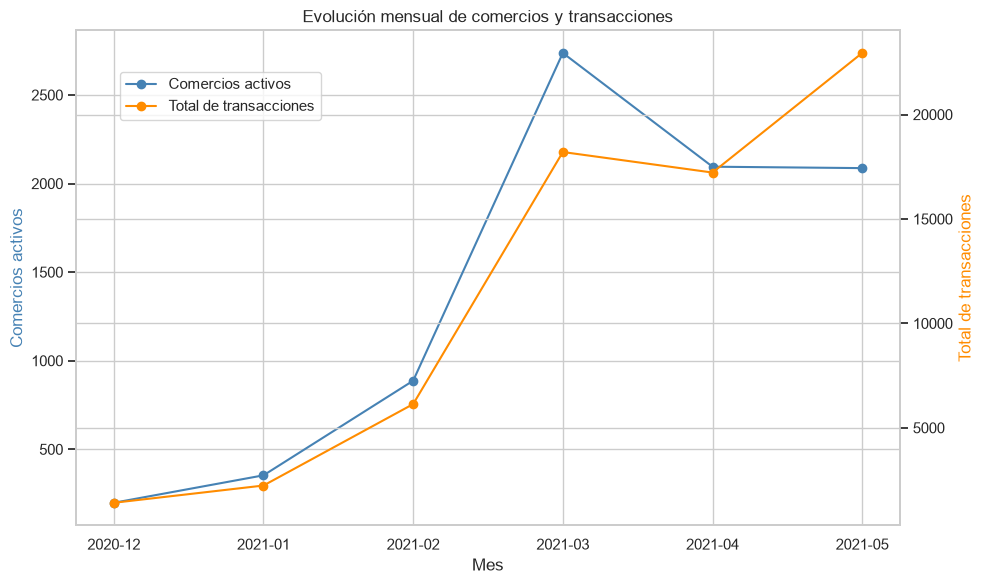

In [18]:
fig, eje_comercios = plt.subplots(figsize=(10, 6))

# Línea de comercios activos
eje_comercios.plot(
    evolucion_mensual["Mes"],
    evolucion_mensual["Comercios_activos"],
    marker="o",
    color="steelblue",
    label="Comercios activos"
)

eje_comercios.set_xlabel("Mes")
eje_comercios.set_ylabel(
    "Comercios activos",
    color="steelblue"
)

# Crear un segundo eje para las transacciones
eje_transacciones = eje_comercios.twinx()

eje_transacciones.plot(
    evolucion_mensual["Mes"],
    evolucion_mensual["Total_transacciones"],
    marker="o",
    color="darkorange",
    label="Total de transacciones"
)

eje_transacciones.set_ylabel(
    "Total de transacciones",
    color="darkorange"
)

plt.title("Evolución mensual de comercios y transacciones")
fig.legend(loc="upper left", bbox_to_anchor=(0.12, 0.88))
plt.tight_layout()
plt.show()

El crecimiento de mayo no se produjo por un aumento en la cantidad de comercios, sino porque los comercios que permanecieron activos realizaron más transacciones.

##### 4.2 Análisis de transacciones 

In [19]:
# Resumir la actividad de cada comercio
transacciones_por_comercio = (
    transacciones.groupby("Id_comercio")
    .agg({
        "cantidad transacciones": "sum",
        "fecha_mes": ["nunique", "max"]
    })
    .reset_index()
)

# Cambiar los nombres de las columnas
transacciones_por_comercio.columns = [
    "Id_comercio",
    "Total_transacciones_6m",
    "Meses_activos",
    "Ultimo_mes_activo"
]

transacciones_por_comercio

,Id_comercio,Total_transacciones_6m,Meses_activos,Ultimo_mes_activo
0,003QDVFJCJ,30,3,2021-05-01
1,008LJH6YHN,10,4,2021-05-01
2,00B3DGV62G,65,3,2021-05-01
3,00ILW1BB3Y,8,3,2021-05-01
4,01AK7UX4UU,4,2,2021-04-01
...,...,...,...,...
3010,ZYU8UUM32R,18,3,2021-05-01
3011,ZYV1ZCZ7IM,11,3,2021-05-01
3012,ZZJ3KWF9VC,5,2,2021-05-01
3013,ZZMG2NE0Q6,4,3,2021-05-01


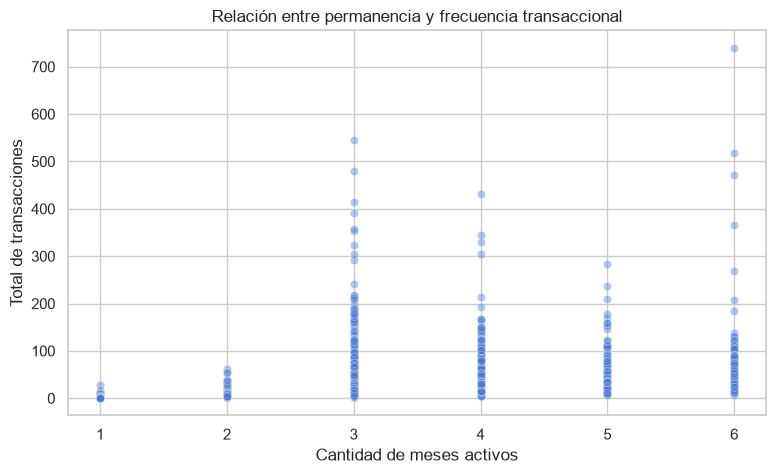

In [20]:
# grafica de distribución
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=transacciones_por_comercio,
    x="Meses_activos",
    y="Total_transacciones_6m",
    alpha=0.4
)

plt.title("Relación entre permanencia y frecuencia transaccional")
plt.xlabel("Cantidad de meses activos")
plt.ylabel("Total de transacciones")
plt.xticks(range(1, 7))
plt.show()

En la gráfica se observa que la mayoría de los comercios tiene una cantidad baja de transacciones, sin importar cuántos meses estuvo activo. Sin embargo, los valores más altos se encuentran principalmente en los comercios que tuvieron actividad durante tres o más meses. También se evidencia que permanecer activo durante más meses no significa necesariamente realizar más transacciones, porque algunos comercios activos durante tres meses presentan una actividad mayor que otros que estuvieron activos durante cinco o seis.

##### 4.3 Análisis de Comercios

In [21]:
# Resumir los comercios y las ventas por categoría
resumen_categorias = (
    comercios.groupby("Categoria comercio")
    .agg({
        "Id_comercio": "nunique",
        "Id_terminal": "nunique",
        "Monto ventas Acumulado": "sum",
        "Monto ventas ultimo mes": "sum"
    })
    .reset_index()
)

# Cambiar los nombres de las columnas
resumen_categorias.columns = [
    "Categoria",
    "Cantidad_comercios",
    "Cantidad_terminales",
    "Ventas_acumuladas",
    "Ventas_ultimo_mes"
]

# Calcular la comisión acumulada de cada categoría
resumen_categorias["Comision_acumulada"] = (
    resumen_categorias["Ventas_acumuladas"] * 0.05
)

# Ordenar desde la categoría con mayores ventas
resumen_categorias = resumen_categorias.sort_values(
    "Ventas_acumuladas",
    ascending=False
)

display(resumen_categorias)

,Categoria,Cantidad_comercios,Cantidad_terminales,Ventas_acumuladas,Ventas_ultimo_mes,Comision_acumulada
2,Comercio detallista,1625,1656,8278729577,1258795662,"413,936,478.85"
5,Servicios,514,525,2124597436,313597881,"106,229,871.80"
0,Alimentos y bebidas,382,390,1129292667,179000803,"56,464,633.35"
4,Reparación y limpieza,167,168,705665517,103403578,"35,283,275.85"
1,Belleza y cuidado personal,206,210,654753707,119952796,"32,737,685.35"
7,Turismo y entretenimiento,35,36,179638588,13502000,"8,981,929.40"
6,Transporte,76,76,113747315,29061205,"5,687,365.75"
3,Educación,10,10,44225525,2012225,"2,211,276.25"


In [22]:
# Ventas en millones de pesos
resumen_categorias["Ventas_millones"] = (
    resumen_categorias["Ventas_acumuladas"] / 1_000_000
)

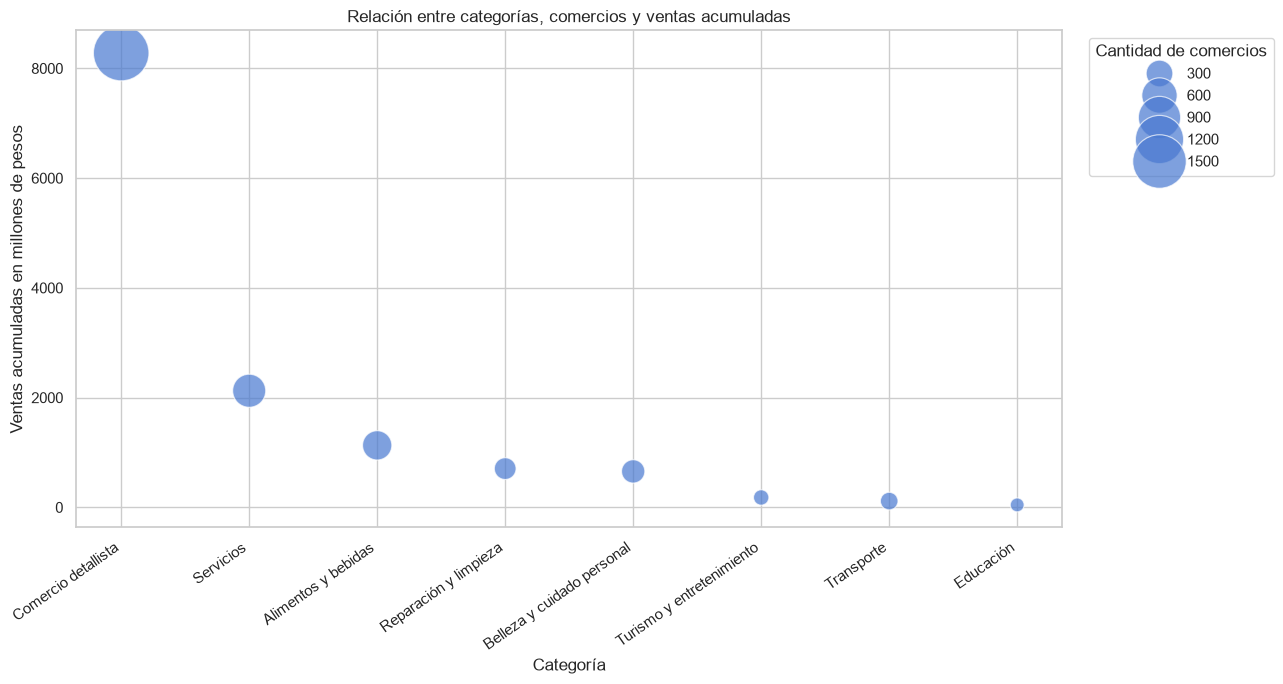

In [23]:
plt.figure(figsize=(13, 7))

grafica = sns.scatterplot(
    data=resumen_categorias,
    x="Categoria",
    y="Ventas_millones",
    size="Cantidad_comercios",
    sizes=(100, 1600),
    alpha=0.7,
    legend="brief"
)

plt.title("Relación entre categorías, comercios y ventas acumuladas")
plt.xlabel("Categoría")
plt.ylabel("Ventas acumuladas en millones de pesos")

# Girar los nombres de las categorías
plt.xticks(rotation=35, ha="right")

# Ubicar la leyenda fuera de la gráfica
plt.legend(
    title="Cantidad de comercios",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [24]:
# Calcular las ventas promedio por comercio en cada categoría
resumen_categorias["Ventas_por_comercio"] = (
    resumen_categorias["Ventas_acumuladas"]
    / resumen_categorias["Cantidad_comercios"]
)

display(
    resumen_categorias[
        [
            "Categoria",
            "Cantidad_comercios",
            "Ventas_acumuladas",
            "Ventas_por_comercio"
        ]
    ].sort_values(
        "Ventas_por_comercio",
        ascending=False
    )
)

,Categoria,Cantidad_comercios,Ventas_acumuladas,Ventas_por_comercio
7,Turismo y entretenimiento,35,179638588,"5,132,531.09"
2,Comercio detallista,1625,8278729577,"5,094,602.82"
3,Educación,10,44225525,"4,422,552.50"
4,Reparación y limpieza,167,705665517,"4,225,542.02"
5,Servicios,514,2124597436,"4,133,458.05"
1,Belleza y cuidado personal,206,654753707,"3,178,416.05"
0,Alimentos y bebidas,382,1129292667,"2,956,263.53"
6,Transporte,76,113747315,"1,496,675.20"


En la gráfica se observa que Comercio detallista concentra la mayor cantidad de comercios y también el mayor valor de ventas acumuladas. Sin embargo, al calcular las ventas por comercio se evidencia que tener más establecimientos no siempre significa generar un mayor valor de forma individual. Turismo y entretenimiento, por ejemplo, solamente tiene 35 comercios, pero presenta el mayor valor promedio por comercio, con aproximadamente $5,1 millones, incluso por encima de Comercio detallista. Por otro lado, Transporte tiene 76 comercios, pero registra el menor valor promedio.

In [25]:
# Información por ciudad
resumen_ciudades = (
    comercios.groupby("Ciudad")
    .agg({
        "Id_comercio": "nunique",
        "Id_terminal": "nunique",
        "Monto ventas Acumulado": "sum",
    })
    .reset_index()
)


resumen_ciudades.columns = [
    "Ciudad",
    "Cantidad_comercios",
    "Cantidad_terminales",
    "Ventas_acumuladas",
]

# Calcular las ventas promedio por terminal
resumen_ciudades["Ventas_por_terminal"] = (
    resumen_ciudades["Ventas_acumuladas"]
    / resumen_ciudades["Cantidad_terminales"]
)

# Calcular las ventas promedio por comercio
resumen_ciudades["Ventas_por_comercio"] = (
    resumen_ciudades["Ventas_acumuladas"]
    / resumen_ciudades["Cantidad_comercios"]
)

# Ordenar por ventas acumuladas
resumen_ciudades = resumen_ciudades.sort_values(
    "Ventas_acumuladas",
    ascending=False
)

display(resumen_ciudades.head(10))

,Ciudad,Cantidad_comercios,Cantidad_terminales,Ventas_acumuladas,Ventas_por_terminal,Ventas_por_comercio
3,Bogotá D.C.,2431,2476,10760605423,"4,345,963.42","4,426,411.12"
51,Soacha,176,182,1287015080,"7,071,511.43","7,312,585.68"
9,Cali,107,107,253150409,"2,365,891.67","2,365,891.67"
26,Fusagasugá,37,39,90231884,"2,313,638.05","2,438,699.57"
38,Melgar,6,6,85670900,"14,278,483.33","14,278,483.33"
7,Cajicá,12,12,70287991,"5,857,332.58","5,857,332.58"
16,Chía,31,31,65047432,"2,098,304.26","2,098,304.26"
15,Choachí,18,19,51389493,"2,704,710.16","2,854,971.83"
44,Pasto,1,1,49127150,"49,127,150.00","49,127,150.00"
27,Girardot,14,14,44052795,"3,146,628.21","3,146,628.21"


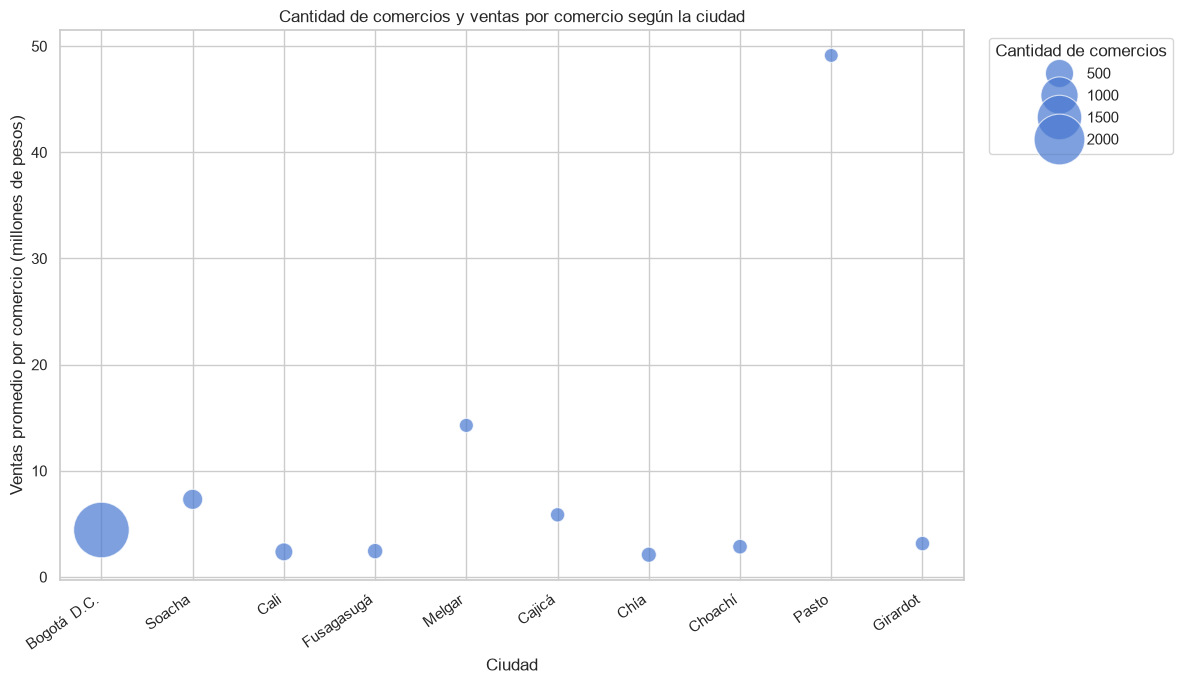

In [26]:
top_ciudades = (
    resumen_ciudades
    .sort_values("Ventas_acumuladas", ascending=False)
    .head(10)
    .copy()
)

# Expresar el valor en millones de pesos
top_ciudades["Ventas_por_comercio_millones"] = (
    top_ciudades["Ventas_por_comercio"] / 1_000_000
)

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=top_ciudades,
    x="Ciudad",
    y="Ventas_por_comercio_millones",
    size="Cantidad_comercios",
    sizes=(100, 1600),
    alpha=0.7
)

plt.title("Cantidad de comercios y ventas por comercio según la ciudad")
plt.xlabel("Ciudad")
plt.ylabel("Ventas promedio por comercio (millones de pesos)")
plt.xticks(rotation=35, ha="right")
plt.legend(
    title="Cantidad de comercios",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

Al comparar las ciudades se observa que Pasto tiene el promedio de ventas por comercio más alto. Sin embargo, este resultado se debe a que en la base solo aparece un comercio de esta ciudad y todas sus ventas se concentran en ese único registro. Bogotá cuenta con la mayor cantidad de comercios y concentra el mayor valor de ventas acumuladas, aunque su promedio por comercio sea más bajo.

##### 4.4. Análisis de ventas y comisiones

In [27]:
# Calcular las comisiones estimadas
ventas_por_comercio["Comision_acumulada"] = (
    ventas_por_comercio["Ventas_acumuladas"] * 0.05
)

ventas_por_comercio["Comision_ultimo_mes"] = (
    ventas_por_comercio["Ventas_ultimo_mes"] * 0.05
)

resumen_ventas = pd.Series({
    "Ventas acumuladas": ventas_por_comercio["Ventas_acumuladas"].sum(),
    "Ventas del último mes": ventas_por_comercio["Ventas_ultimo_mes"].sum(),
    "Comisión acumulada estimada": ventas_por_comercio["Comision_acumulada"].sum(),
    "Comisión estimada del último mes": ventas_por_comercio["Comision_ultimo_mes"].sum()
})

display(resumen_ventas.to_frame(name="Valor"))

,Valor
Ventas acumuladas,"13,230,650,332.00"
Ventas del último mes,"2,019,326,150.00"
Comisión acumulada estimada,"661,532,516.60"
Comisión estimada del último mes,"100,966,307.50"


### Conclusión del EDA

La tabla de transacciones contiene información de diciembre de 2020 a mayo de 2021. Durante este periodo, los 3.015 comercios realizaron 68.152 transacciones y todos presentaron actividad en al menos uno de los seis meses analizados.

Después de consolidar las terminales, las ventas acumuladas reportadas alcanzan $13.230.650.332, lo que representa una comisión estimada de $661.532.516,60, aplicando el 5 %.

El campo de ventas del último mes reporta $2.019.326.150, equivalentes a una comisión de $100.966.307,50. Sin embargo, esta variable no coincide completamente con las transacciones registradas en mayo, por lo que se conservará como un valor reportado sin asignarle un periodo específico.

Si se utiliza este valor como referencia para calcular la meta del negocio, aumentar las comisiones en un 50 % requeriría alcanzar aproximadamente $3.028.989.225 en ventas y una comisión de $151.449.461,25.

También se identificaron 1.233 comercios con ventas del último mes iguales a cero, los cuales pueden representar una oportunidad para campañas de reactivación.

Los resultados permiten continuar con la construcción de una base de segmentación con una fila por comercio, consolidando sus terminales e incorporando variables de ventas, frecuencia, meses activos, recencia, categoría y ciudad.